# Project 3 - Step 3: From an STL part to a voxel model

Steps 1-2 optimized a rectangular box. Now any shape can be used:

**STL file → triangles → voxelize (each voxel = one Hex8 element) → supports & loads → topology optimization**

New core files:
- `topopt3d/stl_io.py` – read/write STL (binary and ASCII), enclosed volume
- `topopt3d/voxelize.py` – voxelization by **ray casting**
- `VoxelMesh.from_stl(path, resolution)` – STL file straight to a finite element mesh
- `mesh.surface_faces()`, `mesh.surface_nodes()`, `mesh.nodes_where(...)` – supports and loads go on the
  outer surface (also needed by the GUI in Step 4)

**How the voxelizer works:** for every column of voxels, a ray is shot along z through the column centre.
Every time the ray crosses a triangle of the surface it goes from outside to inside or back, so a voxel is
*inside* when an **odd** number of crossings lies below its centre. A closed (watertight) surface always
gives an even number of crossings per ray; an odd number means the STL has a gap.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

from topopt3d import VoxelMesh, BoundaryConditions, TOSettings, run_topopt, read_stl, stl_volume
from plotting import plot_stl, plot_voxels, plot_side_view, plot_history

sys.path.insert(0, "examples")
from make_sample_parts import make_all

## 1. Sample parts
No STL files were given, so three are generated (`examples/make_sample_parts.py`):
an exact box (12 triangles), a sphere (r = 10) and a bracket 80 x 40 x 16 with a bolt hole (r = 7).
Replace them with any closed STL file.

box_10x6x4.stl                12 triangles
sphere_r10.stl             15080 triangles
bracket_with_hole.stl      22768 triangles


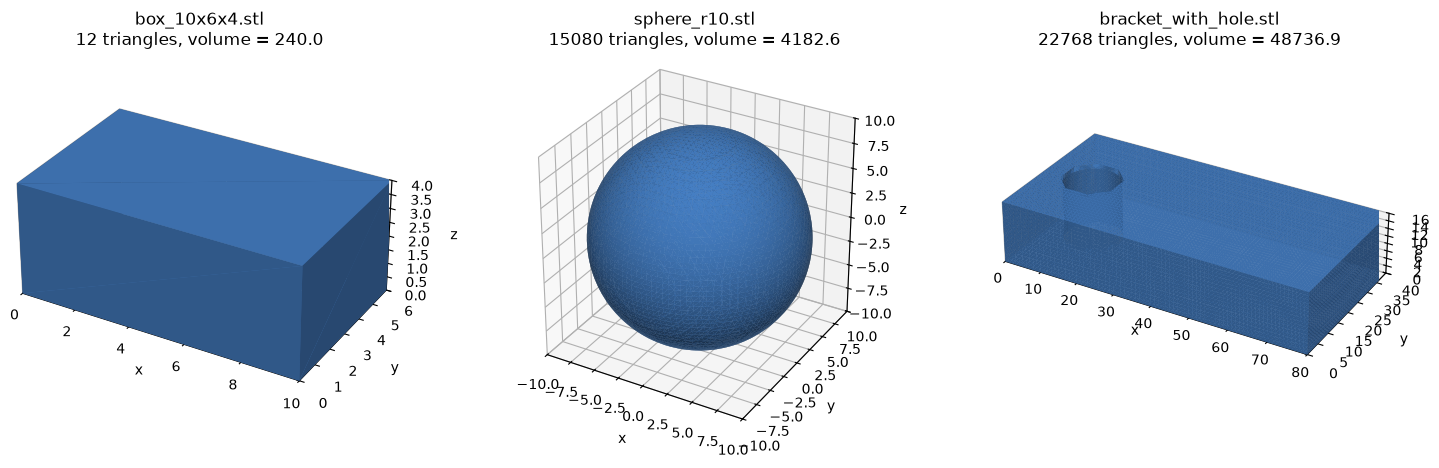

In [2]:
parts = make_all("sample_parts")

fig = plt.figure(figsize=(15, 4.5))
for n, name in enumerate(["box_10x6x4.stl", "sphere_r10.stl", "bracket_with_hole.stl"]):
    tri = read_stl(parts[name])
    plot_stl(tri, f"{name}\n{len(tri)} triangles, volume = {stl_volume(tri):.1f}",
             fig.add_subplot(1, 3, n + 1, projection="3d"))
plt.tight_layout(); plt.show()

## 2. Check the voxelizer: volume vs resolution
`resolution` = number of voxels along the longest side. The voxel volume should approach the STL volume
as the voxels get smaller. The box must be exact.

In [3]:
print(f"{'part':24s} {'res':>4s} {'grid':>14s} {'voxels':>7s} {'voxel vol':>10s} {'STL vol':>9s} {'error':>7s} watertight")
for name, resolutions in [("box_10x6x4.stl", [10]), ("sphere_r10.stl", [10, 20, 40]),
                          ("bracket_with_hole.stl", [20, 40, 80])]:
    for res in resolutions:
        m = VoxelMesh.from_stl(parts[name], resolution=res)
        i = m.info
        print(f"{name:24s} {res:4d} {str(i['shape']):>14s} {i['n_voxels']:7d} {i['voxel_volume']:10.1f} "
              f"{i['stl_volume']:9.1f} {100 * (i['voxel_volume'] / i['stl_volume'] - 1):+6.2f}% {i['watertight']}")

part                      res           grid  voxels  voxel vol   STL vol   error watertight
box_10x6x4.stl             10     (10, 6, 4)     240      240.0     240.0  +0.00% True
sphere_r10.stl             10   (10, 10, 10)     552     4416.0    4182.6  +5.58% True
sphere_r10.stl             20   (20, 20, 20)    4224     4224.0    4182.6  +0.99% True
sphere_r10.stl             40   (40, 40, 40)   33552     4194.0    4182.6  +0.27% True
bracket_with_hole.stl      20    (20, 10, 4)     752    48128.0   48736.9  -1.25% True
bracket_with_hole.stl      40    (40, 20, 8)    6144    49152.0   48736.9  +0.85% True
bracket_with_hole.stl      80   (80, 40, 16)   48704    48704.0   48736.9  -0.07% True


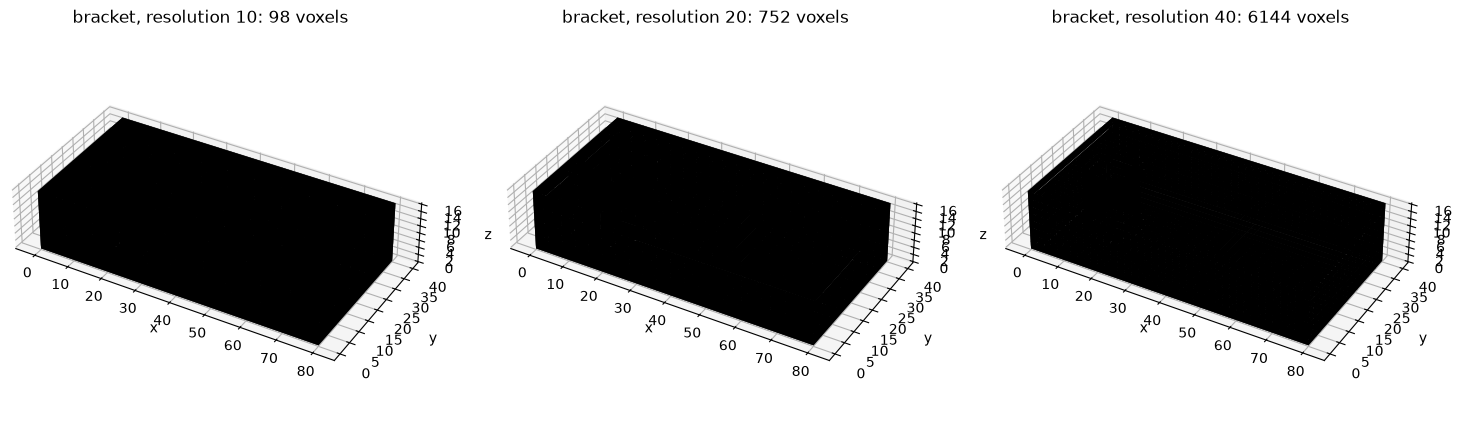

In [5]:
fig = plt.figure(figsize=(15, 4.5))
for n, res in enumerate([10, 20, 40]):
    m = VoxelMesh.from_stl(parts["bracket_with_hole.stl"], resolution=res)
    ax = fig.add_subplot(1, 3, n + 1, projection="3d")
    plot_voxels(m, np.ones(m.n_elem), title=f"bracket, resolution {res}: {m.n_elem} voxels", ax=ax)
    ax.view_init(elev=35, azim=-60)
plt.tight_layout(); plt.show()

## 3. Topology optimization of the bracket
- **Support:** the surface of the bolt hole (all nodes within 7 + 0.75 voxel of the hole axis), fixed in x, y, z
- **Load:** total force 1 downward on the line in the middle of the right face (x = 80, y = 20)
- volfrac = 0.25, penal = 3, rmin = 1.5 elements, E = 1, nu = 0.25

In Step 4 these selections will be made by clicking in the GUI instead of writing conditions.

VoxelMesh(grid 40 x 20 x 8, voxel [2.0, 2.0, 2.0], 6144 elements, 7560 nodes, 22680 DOFs)
support: 248 nodes on the hole surface, load: 9 nodes


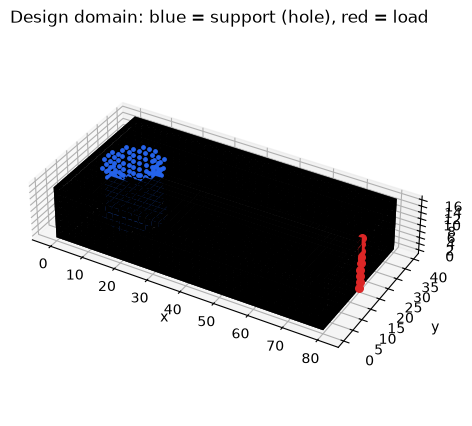

In [8]:
resolution = 40
mesh = VoxelMesh.from_stl(parts["bracket_with_hole.stl"], resolution=resolution)
h = mesh.size[0]
lo, hi = mesh.bounds
print(mesh)

bc = BoundaryConditions(mesh)
hole_nodes = mesh.nodes_where(lambda x, y, z: np.hypot(x - 12, y - 20) < 7 + 0.75 * h)
load_nodes = mesh.nodes_where(lambda x, y, z: (x > hi[0] - 1e-6) & (np.abs(y - 20) < 1e-6))
bc.fix(hole_nodes)
bc.load(load_nodes, (0, -1, 0))
print(f"support: {len(hole_nodes)} nodes on the hole surface, load: {len(load_nodes)} nodes")

ax = plot_voxels(mesh, np.ones(mesh.n_elem), title="Design domain: blue = support (hole), red = load",
                 show_bcs=bc)
ax.view_init(elev=35, azim=-60)
plt.show()

In [9]:
settings = TOSettings(volfrac=0.25, penal=3, rmin=1.5, max_iter=120)

def show_progress(info):
    if info["iter"] % 10 == 0 or info["iter"] == 1:
        print(f"It {info['iter']:3d} | c = {info['c']:8.4f} | vol = {info['vol']:.3f} | change = {info['change']:.4f}")

result = run_topopt(mesh, bc, settings, callback=show_progress)
print(f"converged = {result.converged}, {result.iterations} iterations, {result.time:.1f} s, "
      f"c = {result.compliance:.4f}, solver fallbacks = {result.cg_fallbacks}")

It   1 | c = 153.0160 | vol = 0.250 | change = 0.2000
It  10 | c =  14.8435 | vol = 0.250 | change = 0.2000
It  20 | c =   9.5789 | vol = 0.250 | change = 0.0436
It  30 | c =   9.3995 | vol = 0.250 | change = 0.0205
It  40 | c =   9.3535 | vol = 0.250 | change = 0.0104
converged = True, 41 iterations, 39.9 s, c = 9.3517, solver fallbacks = 0


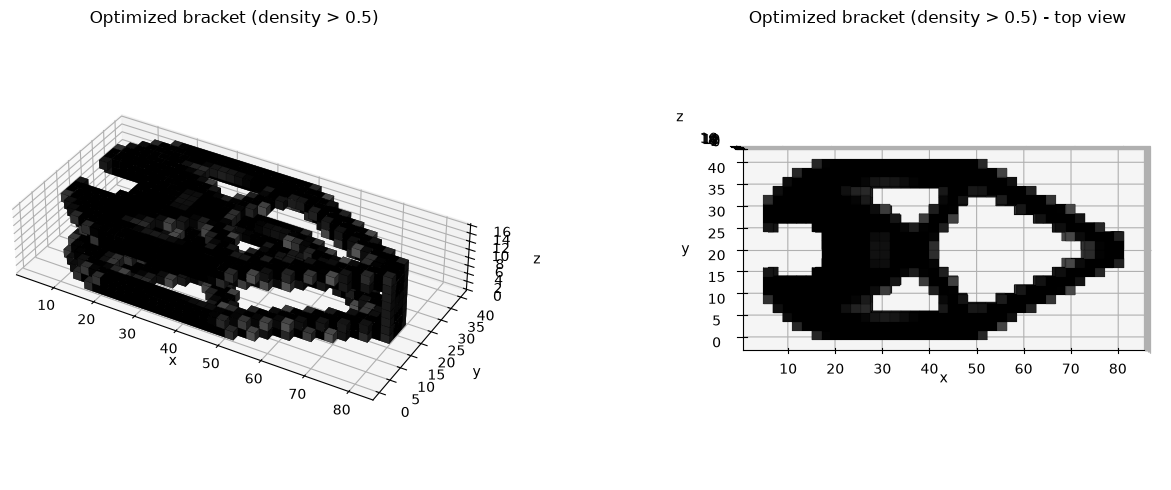

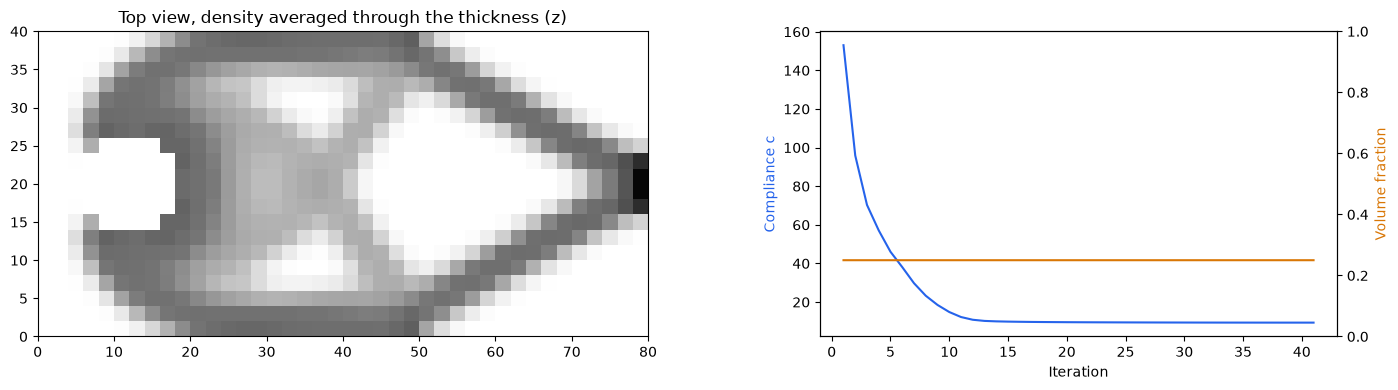

In [12]:
fig = plt.figure(figsize=(16, 5))
for n, (elev, azim) in enumerate([(35, -60), (90, -90)]):
    ax = fig.add_subplot(1, 2, n + 1, projection="3d")
    plot_voxels(mesh, result.x, threshold=0.5, ax=ax,
                title="Optimized bracket (density > 0.5)" + (" - top view" if n else ""))
    ax.view_init(elev=elev, azim=azim)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={"width_ratios": [1.6, 1]})
plot_side_view(mesh, result.x, "Top view, density averaged through the thickness (z)", axes[0])
plot_history(result, axes[1])
plt.tight_layout(); plt.show()

## 4. Try your own STL
Put a closed STL file in the project folder and change the path. Then choose supports and loads with
`mesh.nodes_where(...)` as in section 3.

In [11]:
my_stl = "sample_parts/sphere_r10.stl"      # <- change this
my_mesh = VoxelMesh.from_stl(my_stl, resolution=20)
print(my_mesh)
print(my_mesh.info)

VoxelMesh(grid 20 x 20 x 20, voxel [1.0, 1.0, 1.0], 4224 elements, 5233 nodes, 15699 DOFs)
{'voxel_size': 1.0, 'shape': (20, 20, 20), 'n_voxels': 4224, 'voxel_volume': 4224.0, 'odd_columns': 0, 'watertight': True, 'stl_volume': 4182.567791580067, 'n_triangles': 15080}
